In [32]:
using DelimitedFiles
using Plots
using LaTeXStrings

In [44]:
# For plots
base = 12
lfs = base # Legend font size
alfs = base # axis label font size
tfs = base # title font size
atfs = base # axis ticks font size
ga = 0.3 # grid alpha
sizes =(500,450) # standard size for single plots
rl = 0.065 # position of the "A" or "B" label in % 
ms = 6 # marker size
ls = 6 # line size
annfs = 34
#

34

In [4]:
# Set the data  directory to the parent directory of the script
wdir = dirname(@__DIR__)
cd(wdir)

In [5]:
include("src/misc.jl")
include("src/score.jl")

likelihood_null (generic function with 1 method)

### H3N2-NA

In [50]:
variant="H3N2"
protein="NA";
L=paramAlign(variant,protein)[1];

In [51]:
epitope_positions_munoz=readdlm("data/$variant/$protein/epitope/epitope_positions_munoz_rsa.txt")[:];
epitope_positions_bhatt=readdlm("data/$variant/$protein/epitope/epitope_positions_bhatt.txt")[:];


In [52]:
full_path_freq=readdlm("data/$variant/$protein/frequency/full_path_freq.txt");
h0=readdlm("data/$variant/$protein/results/h_sigma_0_h3n2_na_norm_by_consensus_seq_gamma_20_aa.txt")[:];
enr_bhatt_vs_pct=[]
enr_munoz_vs_pct=[]
q=21
for pct in 0.01:0.01:0.2
top_1pc_filter=filter_top_mutations(h0,pct,full_path_freq,q,L);
    
rr1_,rr2_,enr_=compute_enrichment_aa(top_1pc_filter,Float64.(epitope_positions_munoz),q,L);
push!(enr_munoz_vs_pct,enr_)
    
rr1_,rr2_,enr_=compute_enrichment_aa(top_1pc_filter,Float64.(epitope_positions_bhatt),q,L);
push!(enr_bhatt_vs_pct,enr_)  
    
end   

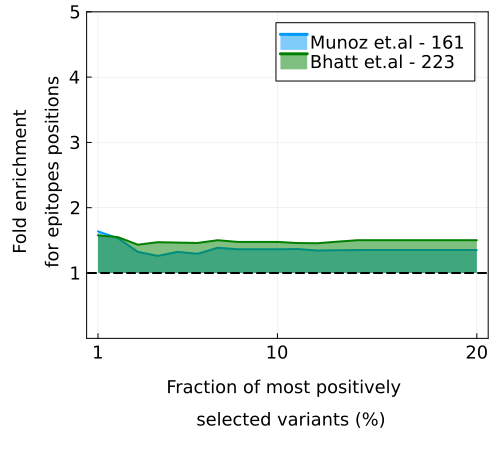

ERROR: syntax error
ERROR: syntax error
ERROR: syntax error
ERROR: syntax error
ERROR: syntax error
ERROR: syntax error
ERROR: syntax error
ERROR: syntax error
ERROR: syntax error
ERROR: syntax error


In [53]:
p=Plots.plot(1:1:20,enr_munoz_vs_pct,fillrange =:true,fillalpha = 0.5, c = 1,color=:blue,linewidth=2,label="Munoz et.al - 161 ")
Plots.plot!(1:1:20,enr_bhatt_vs_pct,fillrange =:true,fillalpha = 0.5,color=:green,linewidth=2,label="Bhatt et.al - 223")
Plots.plot!([1.0],linestyle=:dash,seriestype="hline",alpha=1.0,linewidth=2.0,color=:black,label="")


plot!(p,tickfontsize=tfs, legendfontsize=lfs, guidefontsize=alfs,titlefontsize=alfs)
plot!(p,frame=:box,fmt=:svg,ylim=[0.0,5])
plot!(p, size=sizes,yticks=[1,2,3,4,5],xticks=[1,10,20])

ylabel!(latexstring("Fold enrichment  \n\n for epitopes positions"))
xlabel!(latexstring("\nFraction of most positively \n\n selected variants (%)"))


### H3N2-HA

In [54]:
variant="H3N2"
protein="HA";
L=paramAlign(variant,protein)[1];
q=21;

In [55]:
epitope_positions_luksza=readdlm("data/$variant/$protein/epitope/epitope_positions_luksza.txt")[:];
epitope_positions_koel=readdlm("data/$variant/$protein/epitope/epitope_positions_koel.txt")[:];
epitope_positions_wolf=readdlm("data/$variant/$protein/epitope/epitope_positions_wolf.txt")[:];
epitope_positions_shih=readdlm("data/$variant/$protein/epitope/epitope_positions_shih.txt")[:];

In [56]:
full_path_freq=readdlm("data/$variant/$protein/frequency/full_path_freq.txt");
h0=readdlm("data/$variant/$protein/results/h_sigma_0_h3n2_ha_norm_by_consensus_seq_gamma_20_aa.txt")[:];
enr_koel_vs_pct=[]
enr_wolf_vs_pct=[]
enr_shih_vs_pct=[]
enr_lukza_vs_pct=[]

for pct in 0.01:0.01:0.2
top_1pc_filter=filter_top_mutations(h0,pct,full_path_freq,q,L);
rr1,rr2,enr=compute_enrichment_aa(top_1pc_filter,Float64.(epitope_positions_koel),q,L);
push!(enr_koel_vs_pct,enr)
rr1,rr2,enr=compute_enrichment_aa(top_1pc_filter,Float64.(epitope_positions_wolf),q,L);
push!(enr_wolf_vs_pct,enr)
    
rr1,rr2,enr=compute_enrichment_aa(top_1pc_filter,Float64.(epitope_positions_shih),q,L);
push!(enr_shih_vs_pct,enr)
    
rr1,rr2,enr=compute_enrichment_aa(top_1pc_filter,Float64.(epitope_positions_luksza),q,L);
push!(enr_lukza_vs_pct,enr)
    
end   

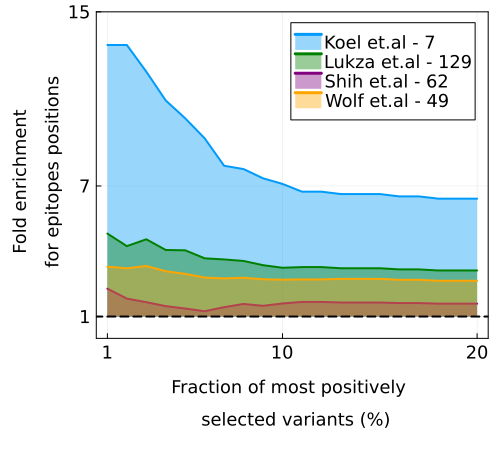

ERROR: syntax error
ERROR: syntax error
ERROR: syntax error
ERROR: syntax error
ERROR: syntax error
ERROR: syntax error
ERROR: syntax error
ERROR: syntax error
ERROR: syntax error
ERROR: syntax error


In [57]:
p=Plots.plot(1:1:20,enr_koel_vs_pct,fillrange =:true,fillalpha = 0.4, c = 1,color=:blue,linewidth=2,label="Koel et.al - 7 ")
Plots.plot!(1:1:20,enr_lukza_vs_pct,fillrange =:true,fillalpha = 0.4,color=:green,linewidth=2,label="Lukza et.al - 129")
Plots.plot!(1:1:20,enr_shih_vs_pct,fillrange =:true,fillalpha = 0.4,color=:purple,linewidth=2,label="Shih et.al - 62")
Plots.plot!(1:1:20,enr_wolf_vs_pct,fillrange =:true,fillalpha = 0.4,color=:orange,linewidth=2,label="Wolf et.al - 49")
Plots.plot!([1.0],linestyle=:dash,seriestype="hline",alpha=1.0,linewidth=2.0,marker=:false,color=:black,label="")



plot!(p,tickfontsize=tfs, legendfontsize=lfs, guidefontsize=alfs,titlefontsize=alfs)
plot!(p,frame=:box,fmt=:svg,ylim=[0.0,15])
plot!(p, size=sizes,yticks=[1,7,15],xticks=[1,10,20])

ylabel!(latexstring("Fold enrichment  \n\n for epitopes positions"))
xlabel!(latexstring("\nFraction of most positively \n\n selected variants (%)"))


#

### H1N1pdm-HA

In [58]:
variant="H1N1pdm"
protein="HA";
L=paramAlign(variant,protein)[1];
q=21;

In [59]:
epitope_positions_ha1_globular_head_HA_H1N1=readdlm("data/$variant/$protein/epitope/epitope_positions_ha1_globular_head.txt")[:];
epitope_positions_canton_HA_H1N1=readdlm("data/$variant/$protein/epitope/epitope_positions_canton.txt")[:];


In [60]:
full_path_freq=readdlm("data/$variant/$protein/frequency/full_path_freq.txt");
h0=readdlm("data/$variant/$protein/results/h_sigma_0_h1n1_ha_norm_by_consensus_seq_gamma_20_aa.txt")[:];
enr_canton_vs_pct=[]
enr_other_vs_pct=[]

for pct in 0.01:0.01:0.2
top_1pc_filter=filter_top_mutations(h0,pct,full_path_freq,q,L);
rr1,rr2,enr=compute_enrichment_aa(top_1pc_filter,epitope_positions_canton_HA_H1N1,q,L);
push!(enr_canton_vs_pct,enr)
rr1,rr2,enr=compute_enrichment_aa(top_1pc_filter,epitope_positions_ha1_globular_head_HA_H1N1,q,L);
push!(enr_other_vs_pct,enr)  
    
end     

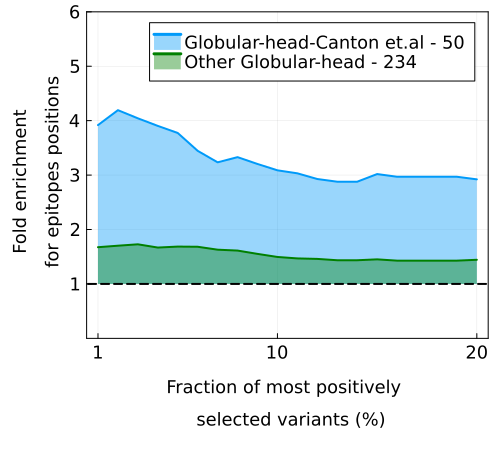

ERROR: syntax error
ERROR: syntax error
ERROR: syntax error
ERROR: syntax error
ERROR: syntax error
ERROR: syntax error
ERROR: syntax error
ERROR: syntax error
ERROR: syntax error
ERROR: syntax error


In [61]:
p=Plots.plot(1:1:20,enr_canton_vs_pct,fillrange =:true,fillalpha = 0.4, c = 1,color=:blue,linewidth=2,label="Globular-head-Canton et.al - 50 ")
Plots.plot!(1:1:20,enr_other_vs_pct,fillrange =:true,fillalpha = 0.4,color=:green,linewidth=2,label="Other Globular-head - 234")
Plots.plot!([1.0],linestyle=:dash,seriestype="hline",alpha=1.0,linewidth=2.0,marker=:false,color=:black,label="")



plot!(p,tickfontsize=tfs, legendfontsize=lfs, guidefontsize=alfs,titlefontsize=alfs)
plot!(p,frame=:box,fmt=:svg,ylim=[0.0,6])
plot!(p, size=sizes,yticks=[1,2,3,4,5,6],xticks=[1,10,20])

ylabel!(latexstring("Fold enrichment  \n\n for epitopes positions"))
xlabel!(latexstring("\nFraction of most positively \n\n selected variants (%)"))




### H1N1pdm-NA

In [73]:
variant="H1N1pdm"
protein="NA";
L=paramAlign(variant,protein)[1];
q=21;

In [74]:
epitope_positions_munoz=readdlm("data/$variant/$protein/epitope/epitope_positions_munoz_rsa.txt")[:];
epitope_positions_bhatt=readdlm("data/$variant/$protein/epitope/epitope_positions_bhatt.txt")[:];


In [75]:
full_path_freq=readdlm("data/$variant/$protein/frequency/full_path_freq.txt");
h0=readdlm("data/$variant/$protein/results/h_sigma_0_h1n1_na_norm_by_consensus_seq_gamma_20_aa.txt")[:];
enr_bhatt_vs_pct=[]
enr_munoz_vs_pct=[]

for pct in 0.01:0.01:0.2
    top_1pc_filter=filter_top_mutations(h0,pct,full_path_freq,q,L);
    
    rr1,rr2,enr=compute_enrichment_aa(top_1pc_filter,epitope_positions_munoz,q,L);
    push!(enr_munoz_vs_pct,enr)

    rr1,rr2,enr=compute_enrichment_aa(top_1pc_filter,epitope_positions_bhatt,q,L);
    push!(enr_bhatt_vs_pct,enr)  
end   

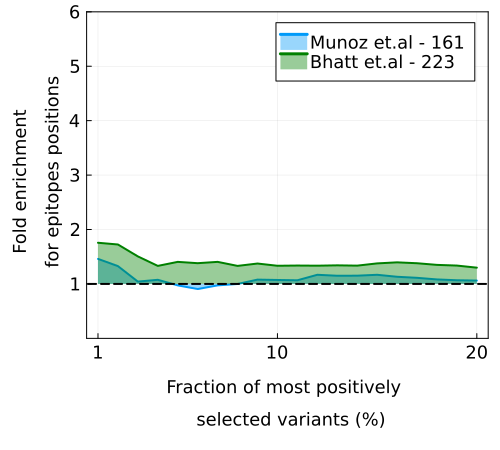

ERROR: syntax error
ERROR: syntax error
ERROR: syntax error
ERROR: syntax error
ERROR: syntax error
ERROR: syntax error
ERROR: syntax error
ERROR: syntax error
ERROR: syntax error
ERROR: syntax error


In [76]:
p=Plots.plot(1:1:20,enr_munoz_vs_pct,fillrange =:true,fillalpha = 0.4, c = 1,color=:blue,linewidth=2,label="Munoz et.al - 161 ")
Plots.plot!(1:1:20,enr_bhatt_vs_pct,fillrange =:true,fillalpha = 0.4,color=:green,linewidth=2,label="Bhatt et.al - 223")
Plots.plot!([1.0],linestyle=:dash,seriestype="hline",alpha=1.0,linewidth=2.0,marker=:false,color=:black,label="")


plot!(p,tickfontsize=tfs, legendfontsize=lfs, guidefontsize=alfs,titlefontsize=alfs)
plot!(p,frame=:box,fmt=:svg,ylim=[0.0,6])
plot!(p, size=sizes,yticks=[1,2,3,4,5,6],xticks=[1,10,20])

ylabel!(latexstring("Fold enrichment  \n\n for epitopes positions"))
xlabel!(latexstring("\nFraction of most positively \n\n selected variants (%)"))
